<div dir="rtl">

# المشروع الختامي: تصميم تجربة وتحليلها

**برنامج التجارب واختبارات A/B والاستدلال السببي**، العرض يوم الأربعاء 11 نوفمبر 2026

تعمل على المشروع **فرديًا أو ضمن فريق صغير** حسب ما يحدده المدرب.

| القسم | موعد كتابته |
|---|---|
| 0. بيانات المشروع، 1. السؤال والفرضية، 2. التصميم | الأحد، الجلسة الرابعة |
| 3. حجم العينة والمدة | الإثنين، الجلسة الرابعة |
| 4. خطة التحليل، 5. إنشاء البيانات، 6. فحوص الثقة، 7. التحليل | الثلاثاء، الجلسة الرابعة |
| 8. (اختياري) بديل شبه تجريبي | الثلاثاء، الجلسة الرابعة |
| 9. التقرير والتوصية | الأربعاء، الجلسة الثانية |
| 10. التسليم على GitHub | آخر اليوم الرابع، الأربعاء |

**المطلوب تسليمه آخر اليوم الرابع:** مستودع عام على GitHub فيه هذا الدفتر مكتملًا وملف README، وتقرير من صفحة واحدة (القسم 9)، وعرض مدته 10 دقائق. خطوات الحفظ في GitHub وقالب README في القسم 10.

> البيانات هنا من **محاكاة**: أنت تحدد الأثر الحقيقي بنفسك، ثم ترى هل يصل تحليلك إليه. في الواقع لا نعرف الأثر الحقيقي، ولهذا نتدرب على المحاكاة أولًا.


أُكمل الدفتر وفق أقسام قالب الأكاديمية مع تكييف التحليل لبوابة خدمة افتراضية.

</div>

<div dir="rtl">

# هل يزيد تبسيط نموذج الخدمة الإلكترونية إتمام الطلبات؟
**زايد الدوسري** · المشروع الختامي لدورة التجارب واختبارات A/B والاستدلال السببي

## 0 · بيانات المشروع
المشروع: تبسيط نموذج خدمة إلكترونية. الإعداد: زايد الدوسري. المنتج: بوابة إصدار إفادة افتراضية.

## 1 · السؤال والفرضية
نختبر نموذجًا لطلب إصدار إفادة إلكترونية في بوابة خدمات افتراضية. A هو النموذج الحالي
من 8 حقول، وB نموذج من 5 حقول مع تعبئة البيانات المعروفة مسبقًا. الفرضية أن B
يرفع نسبة تقديم الطلب دون زيادة تذاكر الدعم أو إعادة الطلبات للتصحيح بما يتجاوز الهوامش.

## 2 · التصميم
نفترض أن معالجة حساب لا تغيّر نتيجة حساب آخر، وأن لكل نسخة تنفيذًا ثابتًا (SUTVA).
- الأهلية: أول فتح لنموذج الخدمة من حساب موثّق خلال التسجيل. يُستبعد موظفو الاختبار قبل التوزيع.
- التوزيع: 50/50 على مستوى الحساب، ثابت باستخدام تجزئة معرّف الحساب ومفتاح تجربة ثابت.
- القياس: تسجيل التخصيص على الخادم قبل عرض النموذج وربط جميع الأحداث بالحساب. يمنع التسجيل المكرر.
- المقياس الرئيسي: أي طلب مقدّم خلال 24 ساعة، على جميع الحسابات الموزعة.
- الحماية: أي تذكرة دعم متعلقة بالنموذج أو أي إرجاع للتصحيح خلال 7 أيام، كل منهما على جميع الموزعين.
- الثانوية الاستكشافية: إتمام الطلب خلال 10 دقائق، وحفظ مسودة خلال 24 ساعة.
- المصدر: محاكاة افتراضية ببذرة ثابتة. الافتراضات تعكس سيناريو تدريبيًا فقط.

</div>


<div dir="rtl">

## 3 · القوة والمدة
نفترض أساسًا 30% وإشارة تصميمية (MDE) قدرها نقطتان مئويتان، وقوة 80% واختبارًا ثنائي الطرف عند 5%.
الحماية مصممة بهامش +0.8 نقطة للدعم (أساس 4%) و+0.6 نقطة للتصحيح (أساس 2%) عند أثر صفري.
نستخدم حد ثقة علويًا أحادي الطرف 97.5% لكل حماية لضبط خطأ العائلة عند 5%.
القوة 80% تخص اكتشاف الأثر مقارنة بالصفر. إثبات تجاوزه عتبة الإطلاق +1 نقطة يحتاج قوة منفصلة.
التسجيل يمتد أسبوعين كاملين مع أسبوع إضافي لمتابعة آخر حساب، ثم تحليل واحد بعد الإغلاق.

</div>


In [1]:
import hashlib
from math import ceil, sqrt

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2, norm

BASELINE, MDE = 0.30, 0.02
p1 = BASELINE + MDE
mid = (BASELINE + p1) / 2
z_alpha, z_power = norm.ppf(.975), norm.ppf(.80)
n_primary = ceil((
    z_alpha * sqrt(2 * mid * (1 - mid))
    + z_power * sqrt(BASELINE * (1 - BASELINE) + p1 * (1 - p1))
)**2 / MDE**2)
guards = {"support": (.04, .008), "rework": (.02, .006)}
n_guards = {
    name: ceil(2 * base * (1-base) * (z_alpha + z_power)**2 / margin**2)
    for name, (base, margin) in guards.items()
}
daily_users = 1600
enrollment_days = 14
planned_n = enrollment_days * daily_users
print(f"Primary n/arm: {n_primary:,}; guardrails n/arm: {n_guards}")
print(f"Planned total: {planned_n:,}; enrollment: 14 days; final readout: day 21.")
for days in (7, 14):
    mde = (z_alpha + z_power)*sqrt(2*BASELINE*(1-BASELINE)/(days*daily_users/2))
    print(f"{days} days: approximate MDE vs zero = {100*mde:.2f} pp")
assert planned_n // 2 >= max(n_primary, *n_guards.values())

Primary n/arm: 8,394; guardrails n/arm: {'support': 9419, 'rework': 8547}
Planned total: 22,400; enrollment: 14 days; final readout: day 21.
7 days: approximate MDE vs zero = 2.43 pp
14 days: approximate MDE vs zero = 1.72 pp


<div dir="rtl">

## 4 · خطة التحليل قبل النتائج
تحليل النية للمعالجة (ITT): نقارن حسب التخصيص حتى عند عدم العرض أو عدم الإتمام.
فحص A/A تجريبي مستقل على نسختين متطابقتين، ثم اختبار اختلال التوزيع (SRM) عند 0.01.
نفحص التكرار واكتمال التخصيص والأحداث واتزان نشاط ما قبل التجربة. عند فشل الفحوص نوقف قرار الإطلاق ونراجع القياس.
نقدّر فرق النسب B−A بفترة ثقة 95% واختبار فرق ثنائي الطرف. نعرض CUPED كفحص حساسية،
ونستخدم تصحيح Benjamini–Hochberg للمقياسين الثانويين. نفحص فرق الأثر بين الأسبوعين وصفيًا.
الحد الأدنى العملي للإطلاق +1 نقطة مئوية. نوصي بتجربة ميدانية فقط إذا تجاوز الحد السفلي للأثر هذا الحد
وكانت الحدود العليا لمقاييس الحماية أقل من هوامشها. إذا قطع فاصل الأثر الحد العملي فالنتيجة غير حاسمة،
وإذا كان حده الأعلى دونه فالأثر غير كافٍ. فشل إثبات سلامة أي حماية يوقف قرار الإطلاق.

## 5 · توليد البيانات
فروض المحاكاة: النسخة B ترفع احتمال الإتمام 2.5 نقطة في المتوسط وتزيد الدعم 0.1 نقطة
والتصحيح 0.1 نقطة تقريبًا. تظل أحداث الإتمام السريع والتصحيح ضمن الطلبات المقدمة في المحاكاة.

</div>


In [2]:
def assign(account, experiment):
    digest = hashlib.sha256(f"{experiment}|{account}".encode()).digest()
    return "B" if digest[0] < 128 else "A"


def simulate(n, experiment, seed, identical=False):
    rng = np.random.default_rng(seed)
    accounts = [f"acct-{i:06}" for i in range(n)]
    arm = np.array([assign(i, experiment) for i in accounts])
    treatment = (arm == "B") & (not identical)
    day = np.repeat(np.arange(1, n // daily_users + 1), daily_users)
    prior = rng.binomial(1, .40, n)
    complete = rng.random(n) < (.30 + .10 * (prior - .40) + .025 * treatment)
    support = rng.random(n) < (.04 + .001 * treatment)
    rework = complete & (rng.random(n) < (.0667 - .0021 * treatment))
    fast = complete & (rng.random(n) < (.46 + .04 * treatment))
    draft = rng.random(n) < (.18 - .012 * treatment)
    return pd.DataFrame(dict(account=accounts, arm=arm, day=day, prior=prior, complete=complete,
                             support=support, rework=rework, fast=fast, draft=draft))


aa = simulate(8000, "form-aa-v1", 81, identical=True)
data = simulate(planned_n, "form-ab-v1", 20261111)

<div dir="rtl">

## 6 · فحوص الثقة
الفرق والتباين على مستوى الحساب المستقل. نعرض قيم A وB والأثر المطلق بالنقاط المئوية.
نستخدم تقريبًا طبيعيًا لكبر العينة. حد الحماية العلوي الأحادي 97.5% يساوي الحد العلوي لفترة 95% ثنائية الطرف.

</div>


In [3]:
def srm(frame):
    counts = frame.arm.value_counts().reindex(["A", "B"], fill_value=0)
    expected = len(frame) / 2
    return counts.to_dict(), float(chi2.sf(((counts - expected)**2 / expected).sum(), 1))


def difference(frame, metric):
    a = frame.loc[frame.arm == "A", metric]
    b = frame.loc[frame.arm == "B", metric]
    p_a, p_b = float(a.mean()), float(b.mean())
    delta = p_b - p_a
    se = sqrt(a.astype(float).var()/len(a) + b.astype(float).var()/len(b))
    return dict(A=p_a, B=p_b, delta=delta, lower=delta-z_alpha*se,
                upper=delta+z_alpha*se, p=float(2*norm.sf(abs(delta/se))))


def benjamini_hochberg(p_values):
    adjusted, running = {}, 1.0
    ranked = sorted(p_values.items(), key=lambda pair: pair[1], reverse=True)
    for rank, (name, p) in zip(range(len(ranked), 0, -1), ranked):
        running = min(running, len(ranked)*p/rank)
        adjusted[name] = running
    return adjusted


for frame in (aa, data):
    assert frame.account.is_unique and not frame.isna().any().any()
    assert set(frame.arm) == {"A", "B"}
    assert not (frame.fast & ~frame.complete).any()
    assert not (frame.rework & ~frame.complete).any()

aa_counts, aa_srm = srm(aa)
counts, ab_srm = srm(data)
aa_effect = difference(aa, "complete")
prior_effect = difference(data, "prior")
prior_sd = sqrt(sum(p*(1-p) for p in [prior_effect["A"], prior_effect["B"]])/2)
prior_smd = prior_effect["delta"] / prior_sd
checks_ok = aa_srm >= .01 and ab_srm >= .01 and aa_effect["p"] >= .05 and abs(prior_smd) < .1
print(f"A/A: {aa_counts}, SRM p={aa_srm:.4f}, outcome p={aa_effect['p']:.4f}")
print(f"A/B: {counts}, SRM p={ab_srm:.4f}, pre-period SMD={prior_smd:.4f}")

A/A: {'A': 3947, 'B': 4053}, SRM p=0.2360, outcome p=0.1787
A/B: {'A': 11207, 'B': 11193}, SRM p=0.9255, pre-period SMD=-0.0026


<div dir="rtl">

## 7 · التحليل
التقدير الرئيسي حسب التخصيص، مع CUPED للحساسية. نعرض المقاييس الثانوية مع تصحيح BH.

</div>


In [4]:
results = {key: difference(data, key) for key in ["complete", "support", "rework", "fast", "draft"]}
print(pd.DataFrame(results).T.to_string(float_format=lambda v: f"{v:.5f}"))
secondary = benjamini_hochberg({key: results[key]["p"] for key in ["fast", "draft"]})
print("BH adjusted:", secondary)

theta = data.complete.astype(float).cov(data.prior) / data.prior.var()
data["cuped"] = data.complete.astype(float) - theta*(data.prior-data.prior.mean())
cuped = difference(data, "cuped")
variance_ratio = ((cuped["upper"]-cuped["lower"])/(results["complete"]["upper"]-results["complete"]["lower"]))**2
print(f"CUPED: {cuped['delta']*100:+.3f} pp [{cuped['lower']*100:+.3f}, {cuped['upper']*100:+.3f}]")
print(f"Estimated variance reduction: {1-variance_ratio:.2%}")
weekly = [difference(data.loc[week], "complete") for week in [data.day <= 7, data.day > 7]]
for index, row in enumerate(weekly, 1):
    print(f"Week {index}: {100*row['delta']:+.2f} pp [{100*row['lower']:+.2f}, {100*row['upper']:+.2f}]")
weekly_difference = weekly[1]["delta"]-weekly[0]["delta"]
weekly_half_width = sqrt(sum((w["upper"]-w["delta"])**2 for w in weekly))
print(f"Week 2 minus 1: {100*weekly_difference:+.2f} pp ± {100*weekly_half_width:.2f}")

               A       B    delta    lower    upper       p
complete 0.30811 0.31957  0.01146 -0.00069  0.02362 0.06450
support  0.04176 0.04172 -0.00004 -0.00528  0.00520 0.98892
rework   0.01874 0.02100  0.00226 -0.00140  0.00591 0.22615
fast     0.14312 0.15805  0.01492  0.00555  0.02429 0.00179
draft    0.17998 0.16600 -0.01398 -0.02389 -0.00408 0.00567
BH adjusted: {'draft': 0.005669146914747177, 'fast': 0.0035873241893320212}
CUPED: +1.158 pp [-0.051, +2.368]
Estimated variance reduction: 1.00%
Week 1: +0.98 pp [-0.74, +2.69]
Week 2: +1.30 pp [-0.43, +3.03]
Week 2 minus 1: +0.32 pp ± 2.43


<div dir="rtl">

### 7.3 · قاعدة القرار والأثر المالي
نموذج مالي مبسط: لكل طلب مكتمل إضافي منفعة تقديرية قدرها 18 ريالًا،
مع كلفة 8 ريالات لكل تذكرة دعم إضافية و12 ريالًا لكل إرجاع إضافي.
نحتسب صافي القيمة لكل حساب مباشرة لحفظ التغاير بين المقاييس، ثم نضربه في 10,000 حساب.
جميع القيم الوحدوية افتراضية. الفترة تعكس عدم يقين العينة تحت هذه القيم فقط.

</div>


النتيجة غير حاسمة عند الحد العملي.
Guardrails: {'support': np.True_, 'rework': np.True_}
Net value per 10,000 accounts: SAR 1,796 [-381, 3,972]


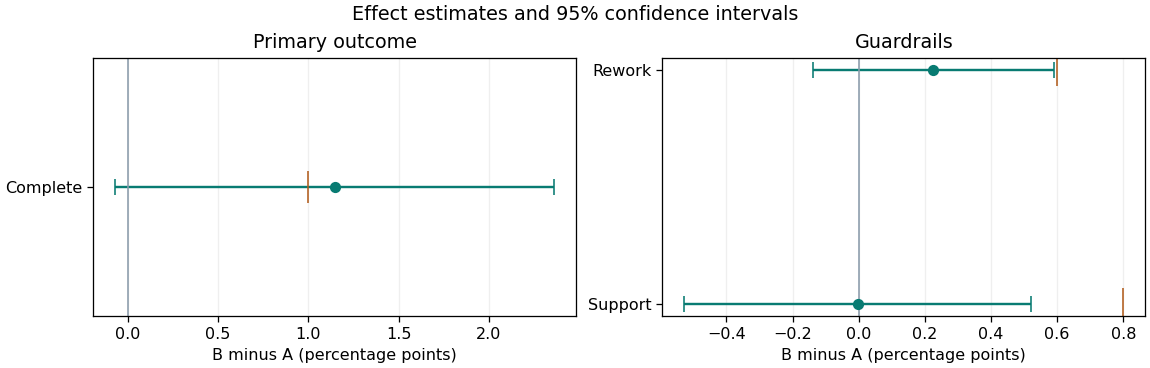

In [5]:
main = results["complete"]
guard_ok = {key: results[key]["upper"] < margin for key, (_, margin) in guards.items()}
launch = checks_ok and all(guard_ok.values()) and main["lower"] > .01
if not checks_ok:
    decision = "راجع جودة البيانات قبل أي قرار."
elif not all(guard_ok.values()):
    decision = "أوقف الإطلاق إلى حين إثبات سلامة مقاييس الحماية."
elif launch:
    decision = "انتقل إلى تجربة ميدانية محدودة بعد التحقق من القياس."
elif main["upper"] < .01:
    decision = "الأثر أقل من الحد العملي للإطلاق."
else:
    decision = "النتيجة غير حاسمة عند الحد العملي."

net = 18*data.complete.astype(int) - 8*data.support.astype(int) - 12*data.rework.astype(int)
a, b = net[data.arm == "A"], net[data.arm == "B"]
net_delta = (b.mean() - a.mean())*10000
net_se = sqrt(a.var()/len(a) + b.var()/len(b))*10000
net_interval = (net_delta-z_alpha*net_se, net_delta+z_alpha*net_se)
print(decision)
print("Guardrails:", guard_ok)
print(f"Net value per 10,000 accounts: SAR {net_delta:,.0f} [{net_interval[0]:,.0f}, {net_interval[1]:,.0f}]")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
for ax, keys in zip(axes, [["complete"], ["support", "rework"]]):
    for index, key in enumerate(keys):
        row = results[key]
        ax.errorbar(row["delta"]*100, index, xerr=[[(row["delta"]-row["lower"])*100],
                    [(row["upper"]-row["delta"])*100]], fmt="o", color="#087b72", capsize=5)
        ax.plot(100*(.01 if key == "complete" else guards[key][1]), index,
                marker="|", markersize=20, color="#b25d1d")
    ax.set_yticks(range(len(keys)), [key.title() for key in keys])
    ax.axvline(0, color="#8a9bab", linewidth=1)
    ax.set_xlabel("B minus A (percentage points)")
    ax.set_title("Primary outcome" if len(keys) == 1 else "Guardrails")
    ax.grid(axis="x", alpha=.2)
fig.suptitle("Effect estimates and 95% confidence intervals")
plt.show()

<div dir="rtl">

## 8 · البديل شبه التجريبي (اختياري)
التوزيع العشوائي ممكن لهذا التصميم؛ لذلك اخترنا تجربة A/B.

## 9 · التقرير والتوصية
المحاكاة تتحقق من آلية التحليل وقاعدة القرار تحت فروض معلنة. يفترض التصميم حسابات مستقلة
وثبات التخصيص ودقة أحداث الخادم. قد تتأثر التجربة الحية بالموسمية أو تداخل الحسابات أو أعطال الربط.
قبل التطبيق الفعلي نُشغّل A/A على البوابة ونستبدل معدلات الأساس وقيم التكلفة ببيانات تشغيلية.

**القرار: نؤجل إطلاق النموذج المبسّط.** نتيجة المحاكاة غير حاسمة عند العتبة العملية (+1 نقطة مئوية).

| المقياس | A | B | الأثر B−A وفترة الثقة 95% | التقييم |
|---|---:|---:|---|---|
| إتمام الطلب خلال 24 ساعة | 30.81% | 31.96% | +1.15 نقطة [−0.07، +2.36] | غير حاسم |
| دعم خلال 7 أيام | 4.18% | 4.17% | −0.004 نقطة [−0.53، +0.52] | اجتاز هامش +0.80 |
| إرجاع للتصحيح خلال 7 أيام | 1.87% | 2.10% | +0.23 نقطة [−0.14، +0.59] | اجتاز هامش +0.60 بفارق ضئيل |

- **مع CUPED:** +1.16 نقطة [−0.05، +2.37]. التحسن في الدقة نحو 1% من التباين.
- **صافي القيمة المفترضة:** +1,796 ريالًا لكل 10,000 حساب [−381، +3,972]. عند 100,000 حساب مؤهل سنويًا، نحو +17,956 ريالًا [−3,809، +39,721] قبل تكاليف التطوير.
- **الخطوة التالية:** نتحقق من أحداث البوابة باختبار A/A ميداني، ونخطط لعينة مستقلة بقوة تستهدف تجاوز +1 نقطة. نعطي هامش التصحيح اهتمامًا عند تقدير القوة.
- **القيود:** البيانات اصطناعية والتكاليف وحجم الزيارات مفترضة. الأثر المبرمج +2.50 نقطة يقع فوق الحد الأعلى المقدر في هذه المحاكاة، وهو مثال على أن فاصل 95% قد يفوّت القيمة الحقيقية في سحب واحد. لا نستخدم الأثر المفترض لتجاوز قاعدة القرار.
نسخة PDF وعرض 10 دقائق مرفقان في ملفات المشروع.

## 10 · README والتسليم
يحتوي README على الفكرة وطريقة التشغيل والنتيجة والتوصية ورابط أكاديمية سدايا.

</div>


<div dir="rtl">

## قائمة التسليم

- المستودع عام على GitHub، وفيه الدفتر وملف README مكتملًا.
- رابط المستودع في ملف التقييم.
- الأقسام من 0 إلى 4 مكتوبة، وخطة التحليل مكتوبة قبل إنشاء البيانات.
- فحص نسبة التوزيع سليم، أو سبب الخلل موضح.
- الأثر الرئيسي معه فترة ثقة، والمقاييس الثانوية مصححة.
- حالة كل مقياس من مقاييس الحماية واضحة.
- تقرير الصفحة الواحدة جاهز، والتوصية موجودة في أول شريحة وآخر شريحة من العرض.

</div>